In [19]:
import torch
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

from turbulence.sqg import SQGSolver

In [20]:
# -------------------------
# Parameters
# -------------------------
N = 64
device = "cpu"

dt = 800.0                    # 15 minutes
diff_efold = 30 * 86400.0     # 30 days

In [ ]:
# torch.manual_seed(123)

# # Initial PV: shape (2, N, N)
# pv0 = torch.randn(2, N, N, device=device)

In [ ]:
# # -------------------------
# # Create solver
# # -------------------------
# solver = SQGSolver(
#     pv=pv0,
#     dt=dt,
#     diff_efold=diff_efold,
#     f=1.0e-4,
#     nsq=1.0e-4,
#     L=20.0e6,
#     H=10.0e3,
#     U=30.0,
#     r=0.0,
#     tdiab=10.0 * 86400.0,
#     diff_order=8,
#     symmetric=True,
#     dealias=True,
#     precision="single",
#     device=device,
# )

# # -------------------------
# # Run simulation
# # -------------------------
# snapshots = []
# times = []

# num_steps = 1000
# save_every = 10

# for n in range(num_steps + 1):
#     if n % save_every == 0:
#         pv_now = solver.fields()["pv"].detach().cpu().clone()
#         snapshots.append(pv_now)
#         times.append(solver.time / 86400.0)  # days

#     solver.step()

# print("Final model time in days:", solver.time / 86400.0)

Final model time in days: 9.268518518518519


In [21]:
def make_smooth_random_pv(N, amplitude=1.0, k0=8.0, seed=123, device="cpu"):
    """
    Create smooth random initial PV of shape (2, N, N)
    by filtering white noise in Fourier space.
    """
    torch.manual_seed(seed)

    pv = torch.randn(2, N, N, device=device)

    # Fourier transform
    pv_hat = torch.fft.rfft2(pv)

    # Wavenumber grid
    ky = torch.fft.fftfreq(N, device=device) * N
    kx = torch.fft.rfftfreq(N, device=device) * N
    KX, KY = torch.meshgrid(kx, ky, indexing="xy")
    K2 = KX**2 + KY**2

    # Band-pass-ish filter: remove very high frequencies
    filt = torch.exp(-K2 / k0**2)

    pv_hat = pv_hat * filt

    pv_smooth = torch.fft.irfft2(pv_hat, s=(N, N))

    # Normalize
    pv_smooth = pv_smooth / pv_smooth.std()

    return amplitude * pv_smooth

In [34]:
# 1. Create random/smooth initial PV
pv_random = make_smooth_random_pv(
    N=N,
    amplitude=5.0,
    k0=10.0,
    seed=123,
    device=device,
)

# 2. Create a burn-in solver
burn_solver = SQGSolver(
    pv=pv_random,
    dt=dt,
    diff_efold=diff_efold,
    f=1.0e-4,
    nsq=1.0e-4,
    L=20.0e6,
    H=10.0e3,
    U=30.0,
    r=0.0,
    tdiab=100.0 * 86400.0,
    diff_order=8,
    symmetric=True,
    dealias=True,
    precision="single",
    device=device,
)

# 3. Run burn-in
burn_in_steps = 3000

for _ in range(burn_in_steps):
    burn_solver.step()

In [35]:
# 4. Extract the burned-in physical PV
pv_true0 = burn_solver.fields()["pv"].detach().clone()

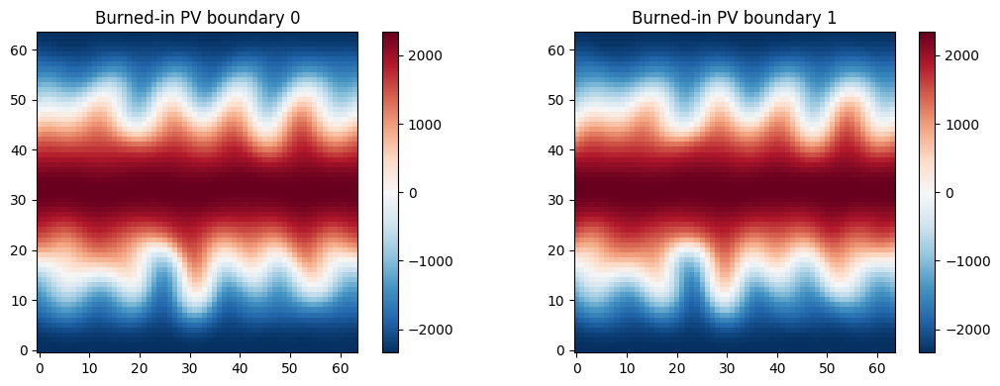

In [36]:
pv_np = pv_true0.detach().cpu().numpy()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

im0 = axes[0].imshow(pv_np[0], origin="lower", cmap="RdBu_r")
axes[0].set_title("Burned-in PV boundary 0")
plt.colorbar(im0, ax=axes[0])

im1 = axes[1].imshow(pv_np[1], origin="lower", cmap="RdBu_r")
axes[1].set_title("Burned-in PV boundary 1")
plt.colorbar(im1, ax=axes[1])

plt.tight_layout()
plt.show()

In [40]:
true_solver = SQGSolver(
    pv=pv_true0,
    dt=dt,
    diff_efold=diff_efold,
    f=1.0e-4,
    nsq=1.0e-4,
    L=20.0e6,
    H=10.0e3,
    U=30.0,
    r=0.0,
    tdiab=100.0 * 86400.0,
    diff_order=8,
    symmetric=True,
    dealias=True,
    precision="single",
    device=device,
)

In [41]:
snapshots = []
times = []

num_steps = 3000
save_every = 10

for n in range(num_steps + 1):
    if n % save_every == 0:
        snapshots.append(true_solver.fields()["pv"].detach().cpu().clone())
        times.append(true_solver.time / 86400.0)

    true_solver.step()

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Fixed color scales for each boundary
vmin0 = min(s[0].min().item() for s in snapshots)
vmax0 = max(s[0].max().item() for s in snapshots)

vmin1 = min(s[1].min().item() for s in snapshots)
vmax1 = max(s[1].max().item() for s in snapshots)

im0 = axes[0].imshow(
    snapshots[0][0].numpy(),
    origin="lower",
    cmap="RdBu_r",
    vmin=vmin0,
    vmax=vmax0,
)

im1 = axes[1].imshow(
    snapshots[0][1].numpy(),
    origin="lower",
    cmap="RdBu_r",
    vmin=vmin1,
    vmax=vmax1,
)

plt.colorbar(im0, ax=axes[0])
plt.colorbar(im1, ax=axes[1])

axes[0].set_title("PV boundary 0")
axes[1].set_title("PV boundary 1")

suptitle = fig.suptitle(f"t = {times[0]:.2f} days")

def update(frame):
    im0.set_data(snapshots[frame][0].numpy())
    im1.set_data(snapshots[frame][1].numpy())
    suptitle.set_text(f"t = {times[frame]:.2f} days")
    return im0, im1, suptitle

anim = FuncAnimation(
    fig,
    update,
    frames=len(snapshots),
    interval=80,
    blit=False,
)

plt.close(fig)

HTML(anim.to_jshtml())

Animation size has reached 21002739 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.


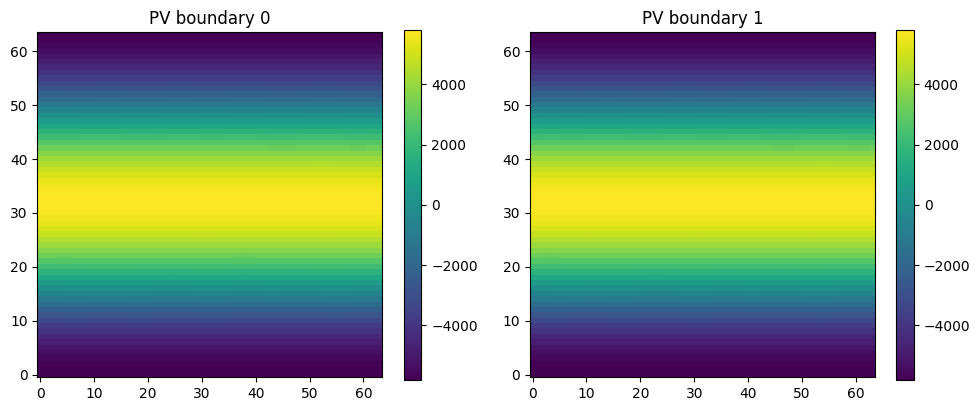

In [ ]:
# # -------------------------
# # Plot final PV
# # -------------------------
# pv_final = snapshots[-1].numpy()

# fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# im0 = axes[0].imshow(pv_final[0], origin="lower")
# axes[0].set_title("PV boundary 0")
# plt.colorbar(im0, ax=axes[0])

# im1 = axes[1].imshow(pv_final[1], origin="lower")
# axes[1].set_title("PV boundary 1")
# plt.colorbar(im1, ax=axes[1])

# plt.tight_layout()
# plt.show()